In [2]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
a549 = sc.read_h5ad("../data/processed/a549_raw.h5ad")

sc.pp.calculate_qc_metrics(a549, inplace=True)


In [3]:
print(a549.obs["total_counts"].describe())
print(a549.obs["n_genes_by_counts"].describe())

NameError: name 'a549' is not defined

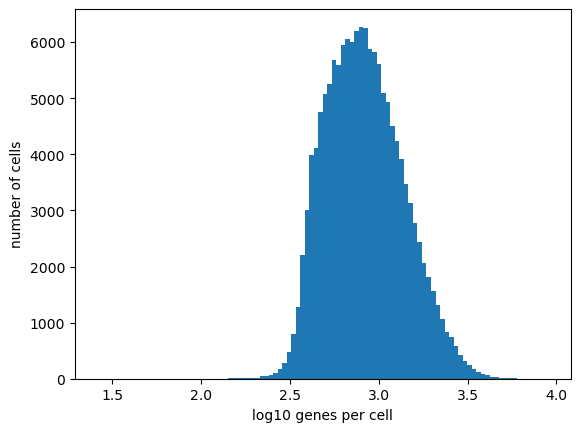

In [ ]:
plt.hist(np.log10(a549.obs["n_genes_by_counts"] + 1), bins=100)
plt.xlabel("log10 genes per cell")
plt.ylabel("number of cells")
plt.show()

In [ ]:
for cut in [100, 200, 300]:
    n = (a549.obs["n_genes_by_counts"] < cut).sum()
    print(cut, "genes ->", n, "cells removed")

top = a549.obs["total_counts"].quantile(0.999)
print("top 0.1% cutoff:", top)
print("cells above:", (a549.obs["total_counts"] > top).sum())

100 genes -> 7 cells removed
200 genes -> 70 cells removed
300 genes -> 745 cells removed
top 0.1% cutoff: 12310.87400000004
cells above: 144


In [ ]:
low = a549.obs["n_genes_by_counts"] < 200
loss = low.groupby(a549.obs["product_dose"]).mean().sort_values(ascending=False)
print(loss.head(10))

product_dose
Bisindolylmaleimide IX (Ro 31-8220 Mesylate)_10000    0.304348
Rigosertib (ON-01910)_10000                           0.117647
Epothilone A_100                                      0.109375
YM155 (Sepantronium Bromide)_10000                    0.100000
Patupilone (EPO906, Epothilone B)_100                 0.088235
Epothilone A_1000                                     0.075472
Ivosidenib (AG-120)_10000                             0.057971
Epothilone A_10                                       0.045977
Patupilone (EPO906, Epothilone B)_10                  0.036145
Rigosertib (ON-01910)_1000                            0.034483
Name: n_genes_by_counts, dtype: float64


/tmp/ipykernel_100891/3281628946.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  loss = low.groupby(a549.obs["product_dose"]).mean().sort_values(ascending=False)


In [ ]:
high = a549.obs["total_counts"] > 12310
loss = high.groupby(a549.obs["product_dose"], observed=True).mean().sort_values(ascending=False)
print(loss.head(10))

product_dose
Rigosertib (ON-01910)_10000                0.058824
KW-2449_10000                              0.043011
Cerdulatinib (PRT062070, PRT2070)_10000    0.035928
PF-573228_10000                            0.027778
Momelotinib (CYT387)_10000                 0.023438
AT9283_10000                               0.022727
Tozasertib (VX-680, MK-0457)_100           0.021277
Gandotinib (LY2784544)_10000               0.021277
AT9283_100                                 0.019608
AT9283_1000                                0.016807
Name: total_counts, dtype: float64


In [ ]:
print("before:", a549.shape)

sc.pp.filter_cells(a549, min_genes=100)
sc.pp.filter_genes(a549, min_cells=50)

print("after:", a549.shape)

before: (143015, 58347)
after: (143008, 21564)


In [ ]:
a549.write_h5ad("../data/processed/a549_qc.h5ad", compression="gzip")
print(a549.shape)

(143008, 21564)


**Normalization**

In [4]:
a549=sc.read_h5ad("../data/processed/a549_qc.h5ad")

In [7]:
sc.pp.normalize_total(a549,target_sum=1e4)
sc.pp.log1p(a549)

In [17]:
a549.write_h5ad("../data/processed/a549_norm.h5ad",compression="gzip")

**Replicate Check**

In [19]:
a549.obs["replicate"].value_counts()

replicate
rep2    83619
rep1    59389
Name: count, dtype: int64

In [23]:
#check control
ctrl = a549[a549.obs["vehicle"] == 1]
print(ctrl.obs["replicate"].value_counts())

replicate
rep2    1927
rep1    1360
Name: count, dtype: int64


In [24]:
r1 = ctrl[ctrl.obs["replicate"] == "rep1"]
r2 = ctrl[ctrl.obs["replicate"] == "rep2"]

mean1 = np.asarray(r1.X.mean(axis=0)).ravel()
mean2 = np.asarray(r2.X.mean(axis=0)).ravel()

In [25]:
#Correlation
r = np.corrcoef(mean1, mean2)[0, 1]
print("control correlation:", round(r, 3))

control correlation: 0.996


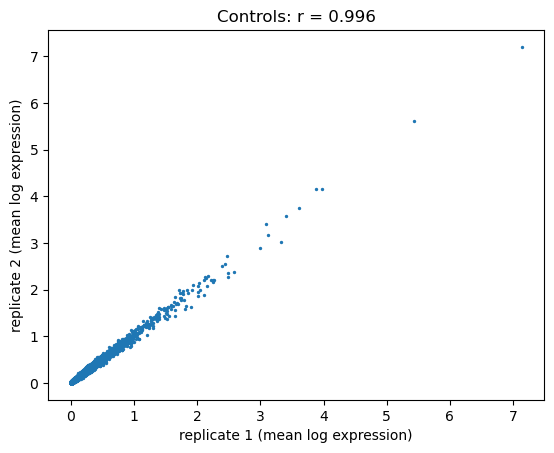

In [26]:
plt.scatter(mean1, mean2, s=2)
plt.xlabel("replicate 1 (mean log expression)")
plt.ylabel("replicate 2 (mean log expression)")
plt.title(f"Controls: r = {r:.3f}")
plt.savefig("../results/figures/02_replicate_controls.png", dpi=150)
plt.show()